# Toluene isotherms on Na-EMT and K-EMT
Processes the FTIR spectra recorded during stepwise toluene dosing on Na-EMT and K-EMT. For each sample, the baseline is corrected, the CH stretching band is integrated and its area is plotted against the equivalent pressure to give an adsorption isotherm.

### Setup
Imports the libraries, sets the Matplotlib defaults (live SVG text, Segoe UI font, label and tick sizes, resolution) and defines three helpers: `save_area_sheet` writes one or several tables to an Excel sheet, `add_minor_ticks` adds minor ticks and removes the top and right axes, and `find_linear_range` returns the number of points before saturation. It also sets the `data` folder path.

In [2]:
import spectrochempy as scp
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path
from scipy import stats
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
from openpyxl.utils import get_column_letter
from openpyxl.styles import Font
import re
from scipy.signal import find_peaks

mpl.rcParams.update({
    "svg.fonttype": "none",
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI"],
    "axes.unicode_minus": True,
    "axes.labelsize": 20,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.dpi": 150,
    "savefig.dpi": 300,
})


def save_area_sheet(tables, sheet_name, path, gap=1):
    """Write one table, or several side by side, to a named sheet of an Excel workbook.

    tables: a DataFrame, or a dict {label: DataFrame}. With a dict, each table gets a
            bold label above it and the tables are separated by `gap` empty columns.
    """
    path = Path(path)
    mode = "a" if path.exists() else "w"
    kwargs = {"if_sheet_exists": "replace"} if mode == "a" else {}

    labelled = isinstance(tables, dict)
    if not labelled:
        tables = {None: tables}

    parts, starts, col = [], {}, 1
    for label, t in tables.items():
        if parts and gap:
            spacer = {" " * (len(parts) + 1): [""] * len(t)}        # unique blank header
            parts.append(pd.DataFrame(spacer))
            col += gap
        starts[label] = col
        parts.append(t.reset_index(drop=True))
        col += t.shape[1]
    combined = pd.concat(parts, axis=1)

    with pd.ExcelWriter(path, engine="openpyxl", mode=mode, **kwargs) as writer:
        combined.to_excel(writer, sheet_name=sheet_name, index=False,
                          startrow=1 if labelled else 0)
        ws = writer.sheets[sheet_name]

        if labelled:
            for label, c in starts.items():
                ws.cell(row=1, column=c, value=label).font = Font(bold=True, size=12)

        for i in range(combined.shape[1]):
            colvals = combined.iloc[:, i]
            width = max(len(str(combined.columns[i])), *(len(str(v)) for v in colvals)) + 2
            ws.column_dimensions[get_column_letter(i + 1)].width = width



def add_minor_ticks(ax=None, nx=4, ny=4):
    ax = ax or plt.gca()
    ax.xaxis.set_minor_locator(AutoMinorLocator(nx))
    ax.yaxis.set_minor_locator(AutoMinorLocator(ny))
    ax.tick_params(which="both", direction="out", top=False, right=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def find_linear_range(x, y, frac=0.5, n_ref=3, min_points=3, consecutive=1):
    """Return n = number of points before saturation.

    Local slope s_i = dy/dx between points i and i+1. The reference slope s0 is
    the median of the first n_ref local slopes. A step counts as saturated if
    s_i < frac * s0. The linear range ends at the first run of `consecutive`
    saturated steps.
    """
    s = np.diff(y) / np.diff(x)
    s0 = np.median(s[:n_ref])
    sat = s < frac * s0
    n = len(y)
    for i in range(len(sat) - consecutive + 1):
        if sat[i:i + consecutive].all():
            n = i + 1                    # points 0..i are kept
            break
    return max(n, min_points), s, s0


UNIT_TO_PA = {"torr": 133.322, "mbar": 100.0, "pa": 1.0}
pattern = re.compile(r"N(\d+)\s*[=_]\s*(\d+(?:[.,]\d+)?)\s*(torr|mbar|pa)", re.IGNORECASE)

def pressures_from_filenames(folder, ext="*.SPA"):
    """Return (file names, pressures in Pa), ordered by the step number N<k> in the name."""
    rows = []
    for f in Path(folder).glob(ext):
        m = pattern.search(f.stem)
        if m is None:
            raise ValueError(f"No pressure found in: {f.name}")
        step = int(m.group(1))
        value = float(m.group(2).replace(",", "."))
        pa = value * UNIT_TO_PA[m.group(3).lower()]
        rows.append((step, f.name, pa))

    rows.sort(key=lambda r: r[0])
    steps = [r[0] for r in rows]
    assert len(set(steps)) == len(steps), f"Duplicate step numbers: {steps}"
    return [r[1] for r in rows], np.array([r[2] for r in rows])

current_directory = os.path.abspath('')
datapath = Path(current_directory, 'data')

### Load the spectra
Reads the Na-EMT and K-EMT isotherm spectra from the data folder into `D_Na` and `D_K`, and creates the output folder for the figures.

In [3]:
data_Na = Path(datapath, "Na-EMT V2/Toluene 18092026/Isotherm")
D_Na = scp.read(data_Na)
data_K = Path(datapath, "K-EMT-V2/Toluene 30092026/Isotherm")
D_K = scp.read(data_K)

outputpath = Path(current_directory, 'output/toluene/isotherm')
outputpath.mkdir(parents=True, exist_ok=True)

<IPython.core.display.Javascript object>

### Label the spectra
Replaces the y axis with the acquisition order (0, 1, 2, ...), so that each spectrum has a simple number.

In [4]:
#D_Na = D_Na[11:]
n_Na = D_Na.shape[0]  # number of spectra (y dimension)
n_K = D_K.shape[0]  # number of spectra (y dimension)

# integers 0, 1, 2, ... in acquisition order
D_Na.y = scp.Coord(np.arange(n_Na), title="spectrum number")
print(D_Na.y)

D_K.y = scp.Coord(np.arange(n_K), title="spectrum number")
print(D_K.y)

Coord: [float64] unitless (size: 18)
Coord: [float64] unitless (size: 11)


### Raw spectra and select the spectral regions
Plots the full spectra of both samples and select the regions of interest

INFO | This coordinate (4000.0) is outside the axis limits (399.193-3999.64).
The closest limit index is returned


<Axes: title={'center': 'K-EMT toluene bending 1620-1340 cm$^{-1}$'}, xlabel='wavenumbers $\\mathrm{/\\ \\mathrm{cm}^{-1}}$', ylabel='absorbance $\\mathrm{/\\ \\mathrm{a.u.}}$'>

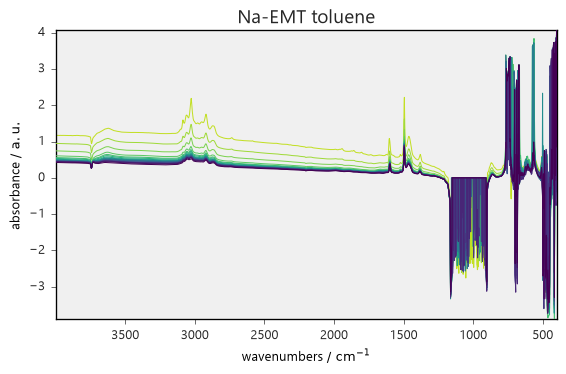

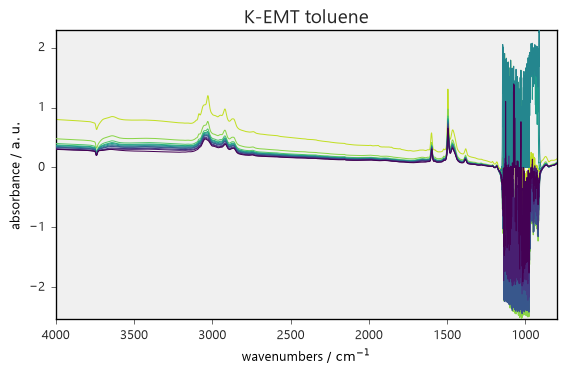

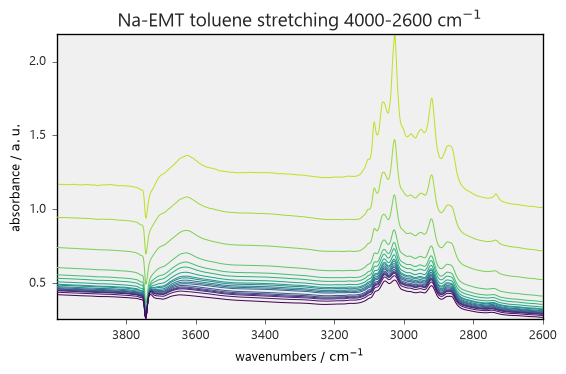

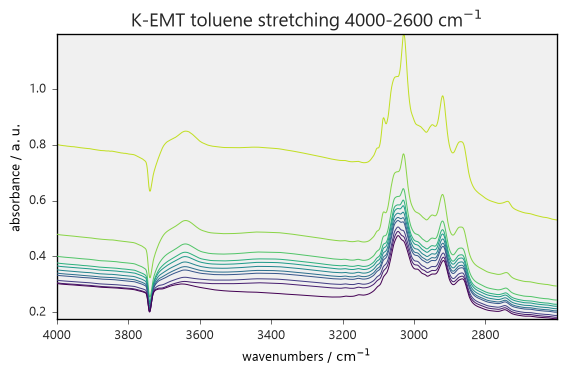

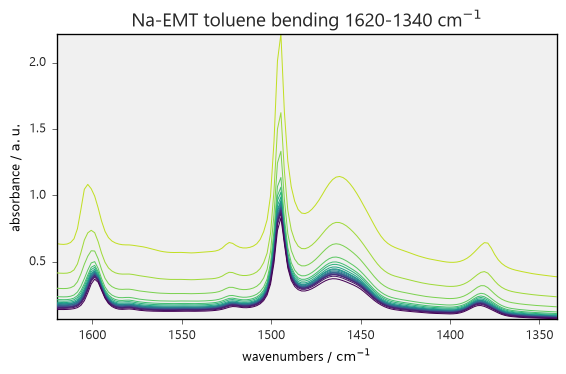

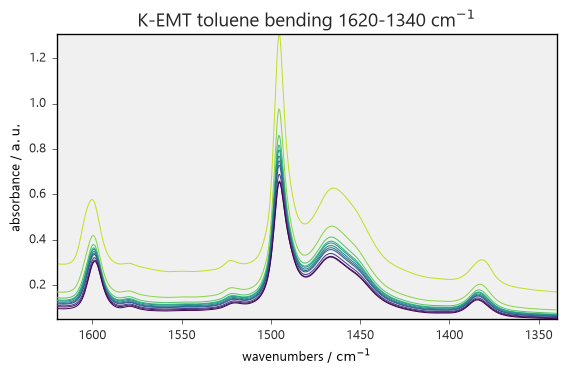

In [5]:
D_Na.plot(title='Na-EMT toluene')
D_K.plot(title='K-EMT toluene')
D_Nastretching = D_Na[:, 4000.:2600.]
D_Kstretching = D_K[:, 4000.:2600.]
D_Nastretching.plot(title='Na-EMT toluene stretching 4000-2600 cm$^{-1}$')
D_Kstretching.plot(title='K-EMT toluene stretching 4000-2600 cm$^{-1}$')
D_Nabending = D_Na[:, 1620.:1340.]
D_Kbending = D_K[:, 1620.:1340.]
D_Nabending.plot(title='Na-EMT toluene bending 1620-1340 cm$^{-1}$')
D_Kbending.plot(title='K-EMT toluene bending 1620-1340 cm$^{-1}$')

### Baseline of the bending region
Fits a linear baseline to the bending region of each sample, using the anchor ranges set in the cell, and plots the corrected spectra with their baselines.


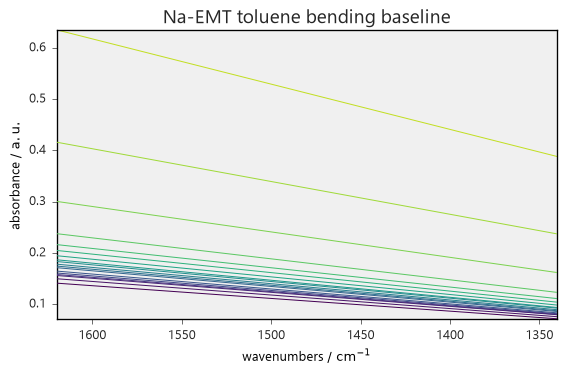

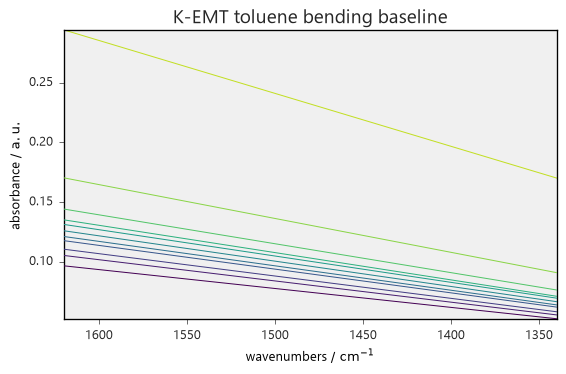

In [6]:
blc = scp.Baseline(model="polynomial", order=1)
_ = blc.fit(D_Nabending)

D_Nabending_corrected = blc.corrected
baseline = blc.baseline
_ = baseline.plot(title='Na-EMT toluene bending baseline')

_ = blc.fit(D_Kbending)
D_Kbending_corrected = blc.corrected
baseline = blc.baseline
_ = baseline.plot(title='K-EMT toluene bending baseline')

### Na-EMT bending peaks
Plots the baseline-corrected bending region and labels the peaks found in the last (highest-dose) spectrum. The figure is saved as SVG.

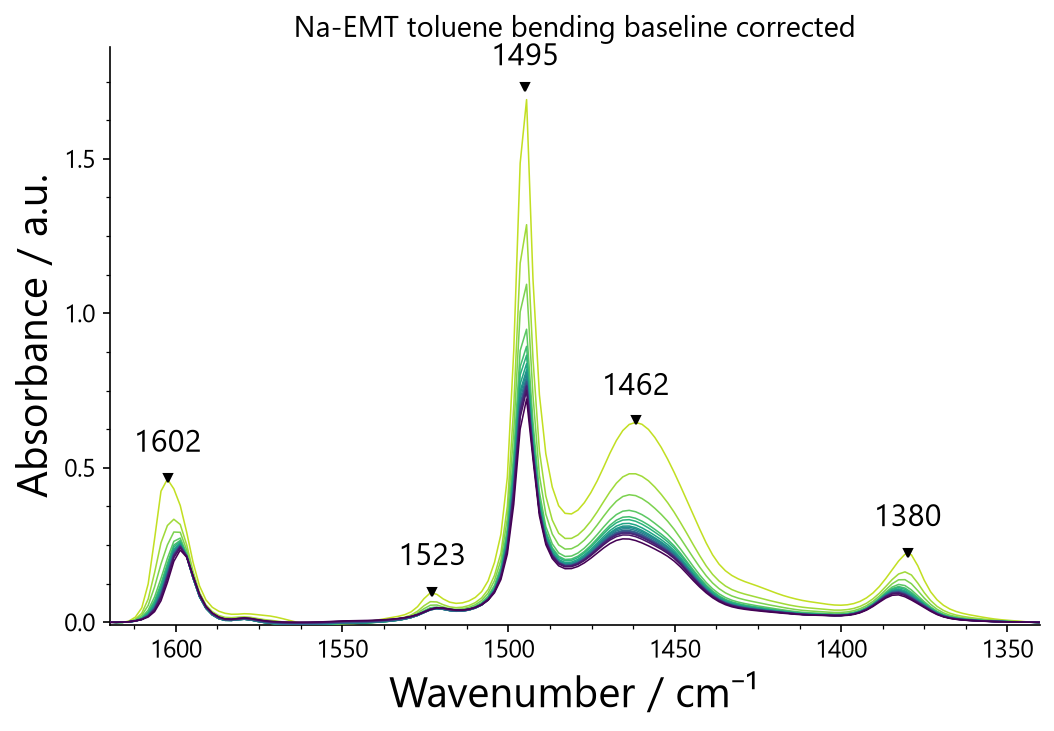

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_Nabending_corrected.plot(ax=ax, title="Na-EMT toluene bending baseline corrected")

spectrum = D_Nabending_corrected[-1]
peaks, props = spectrum.find_peaks(distance="1 cm^-1", prominence=0.01)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 10), textcoords="offset points", rotation=0, va="bottom",
                ha="center", fontsize=15)

ax.set_ylim(np.min(D_Nabending_corrected.data), np.max(D_Nabending_corrected.data) + 0.1*np.max(D_Nabending_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "Na-EMT_toluene_bending_corrected.svg", format="svg", bbox_inches="tight")

### K-EMT bending peaks
Same as above for K-EMT.

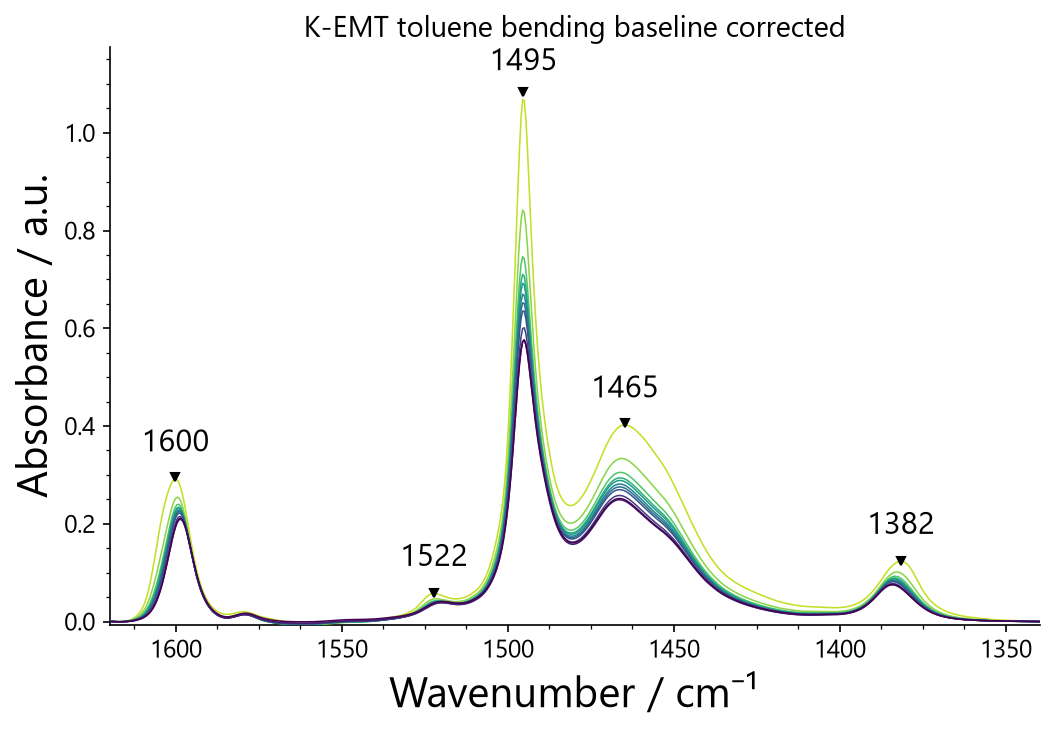

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_Kbending_corrected.plot(ax=ax, title="K-EMT toluene bending baseline corrected")

spectrum = D_Kbending_corrected[-1]
peaks, props = spectrum.find_peaks(distance="1 cm^-1", prominence=0.01)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 10), textcoords="offset points", rotation=0, va="bottom",
                ha="center", fontsize=15)

ax.set_ylim(np.min(D_Kbending_corrected.data), np.max(D_Kbending_corrected.data) + 0.1*np.max(D_Kbending_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "K-EMT_toluene_bending_corrected.svg", format="svg", bbox_inches="tight")

### Baseline of the bending secondary region
Fits a linear baseline for each sample and plots the baselines. The corrected spectra are used for the area integration.


INFO | This coordinate (1625.0) is outside the axis limits (1340.285-1619.912).
The closest limit index is returned
INFO | This coordinate (1625.0) is outside the axis limits (1339.824-1619.939).
The closest limit index is returned


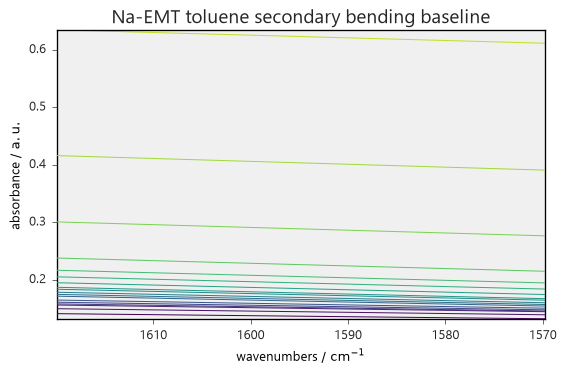

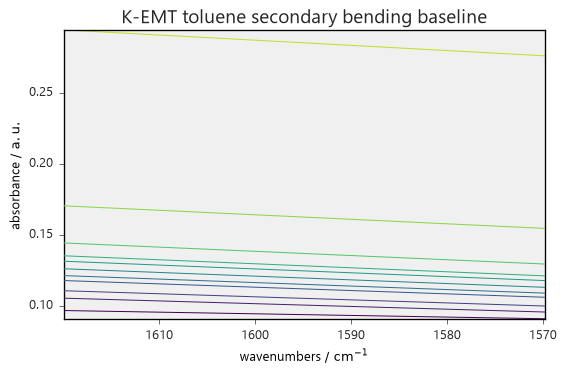

In [9]:
blc = scp.Baseline(model="polynomial", order=1)
_ = blc.fit(D_Nabending[:, 1625.:1570.])

D_Nasecondary_corrected = blc.corrected
baseline = blc.baseline
_ = baseline.plot(title='Na-EMT toluene secondary bending baseline')

_ = blc.fit(D_Kbending[:, 1625.:1570.])
D_Ksecondary_corrected = blc.corrected
baseline = blc.baseline
_ = baseline.plot(title='K-EMT toluene secondary bending baseline')

### Na-EMT bending secondary peaks
Plots the baseline-corrected band and labels the peaks of the last spectrum. The figure is saved as SVG.

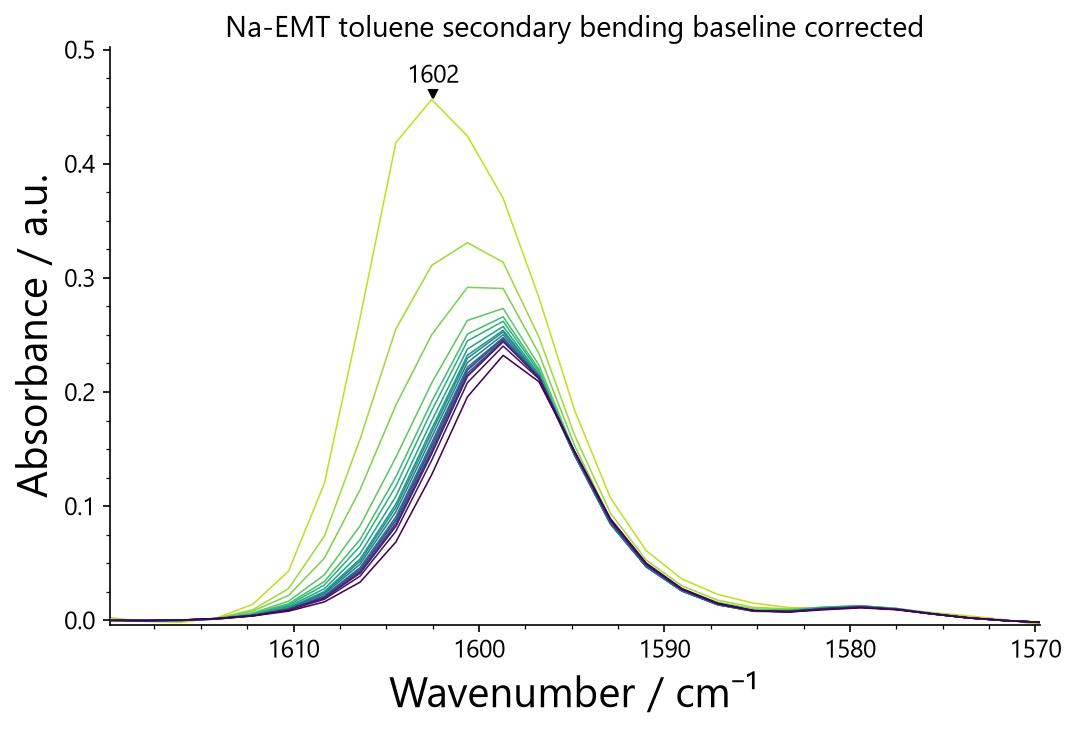

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_Nasecondary_corrected.plot(ax=ax, title="Na-EMT toluene secondary bending baseline corrected")

spectrum = D_Nasecondary_corrected[-1]
peaks, props = spectrum.find_peaks(distance="2 cm^-1", prominence=0.001)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=12)

ax.set_ylim(np.min(D_Nasecondary_corrected.data), np.max(D_Nasecondary_corrected.data) + 0.1*np.max(D_Nasecondary_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "Na-EMT-toluenesecondary_corrected.svg", format="svg", bbox_inches="tight")

### K-EMT peaks
Same as above for K-EMT.

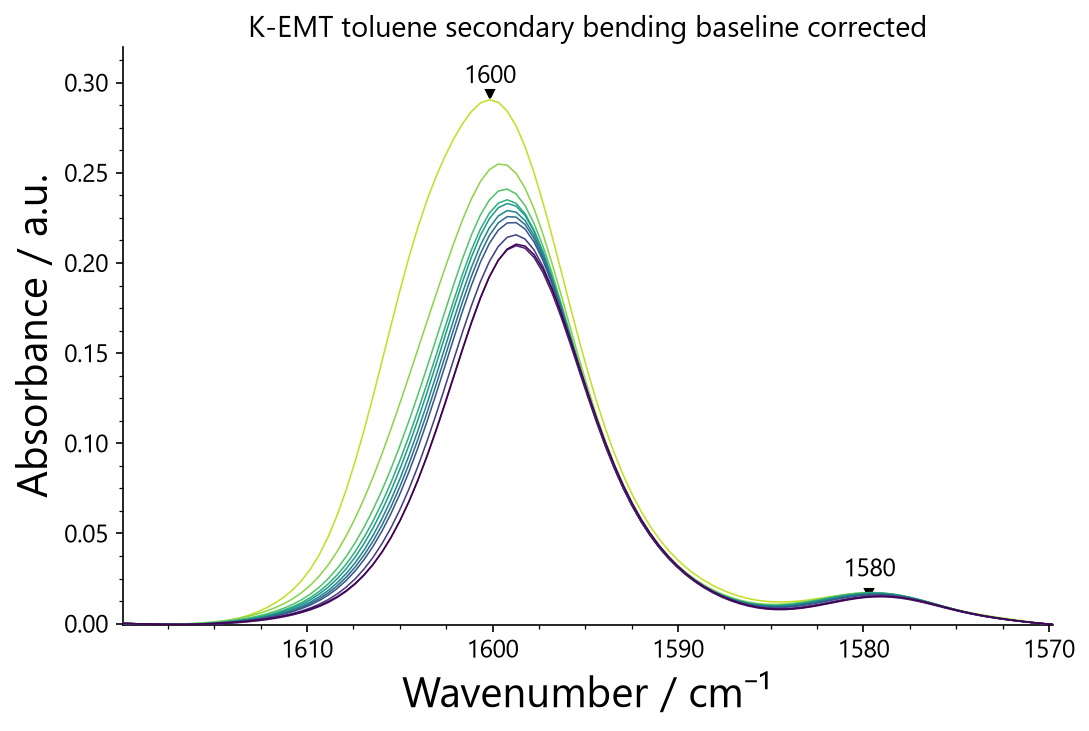

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_Ksecondary_corrected.plot(ax=ax, title="K-EMT toluene secondary bending baseline corrected")

spectrum = D_Ksecondary_corrected[-1]
peaks, props = spectrum.find_peaks(distance="2 cm^-1", prominence=0.001)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=12)

ax.set_ylim(np.min(D_Ksecondary_corrected.data), np.max(D_Ksecondary_corrected.data) + 0.1*np.max(D_Ksecondary_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "K-EMT-toluenesecondary_corrected.svg", format="svg", bbox_inches="tight")

### Integrate the areas

In [12]:
area_Na_toluenesecondary = D_Nasecondary_corrected.trapezoid(dim="x")
area_K_toluenesecondary = D_Ksecondary_corrected.trapezoid(dim="x")

### Na-EMT isotherm
Identifies the pressure from the spectra name and then converts the equivalent pressures to Pa and plots the bending secondary area against pressure. The figure is saved as SVG.

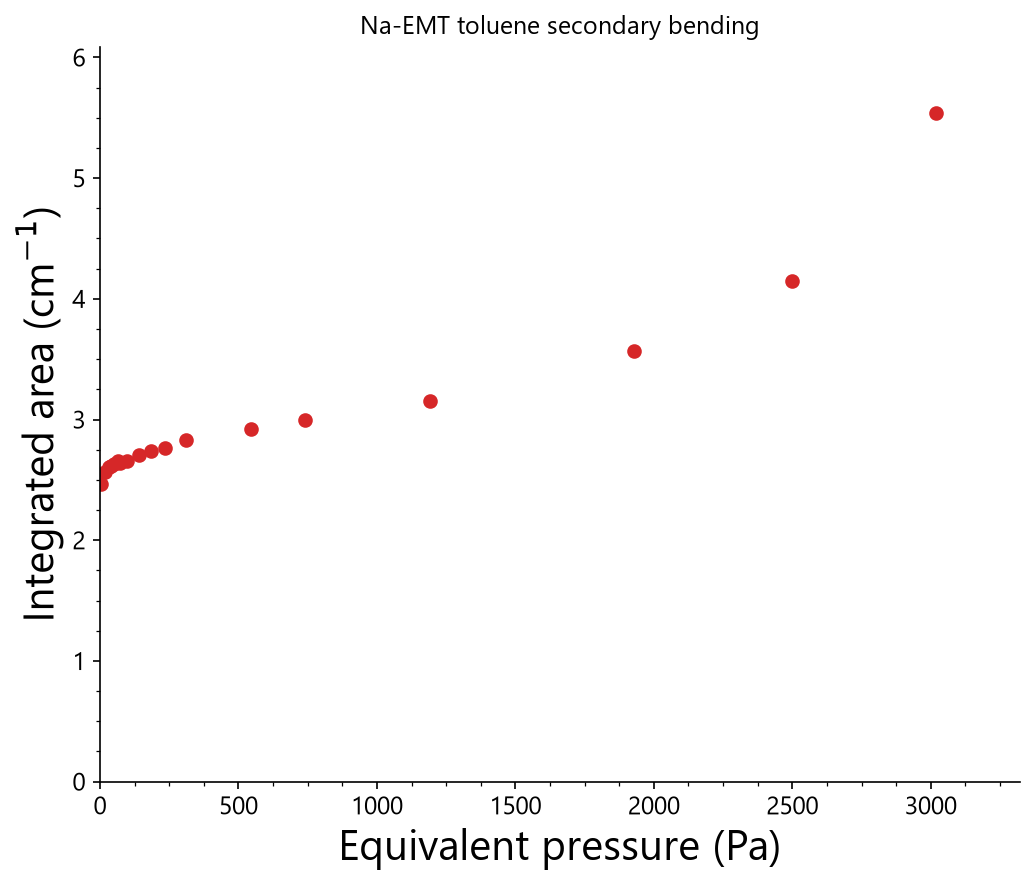

In [13]:
names_Na, x_Na = pressures_from_filenames(data_Na)

y_Na = np.abs(np.asarray(area_Na_toluenesecondary.data)).ravel()

fig, ax1 = plt.subplots(1, 1, figsize=(7, 6))
ax1.plot(x_Na, y_Na, "o", color="C3")
ax1.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax1.set_xlabel("Equivalent pressure (Pa)")
ax1.set_title(f"Na-EMT toluene secondary bending")
ax1.set_xlim(0, max(x_Na) + 0.1*max(x_Na))
ax1.set_ylim(0, max(y_Na) + 0.1*max(y_Na))
add_minor_ticks(ax1)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT-toluene_secondary_bending_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

### K-EMT isotherm
Same as previous cell.


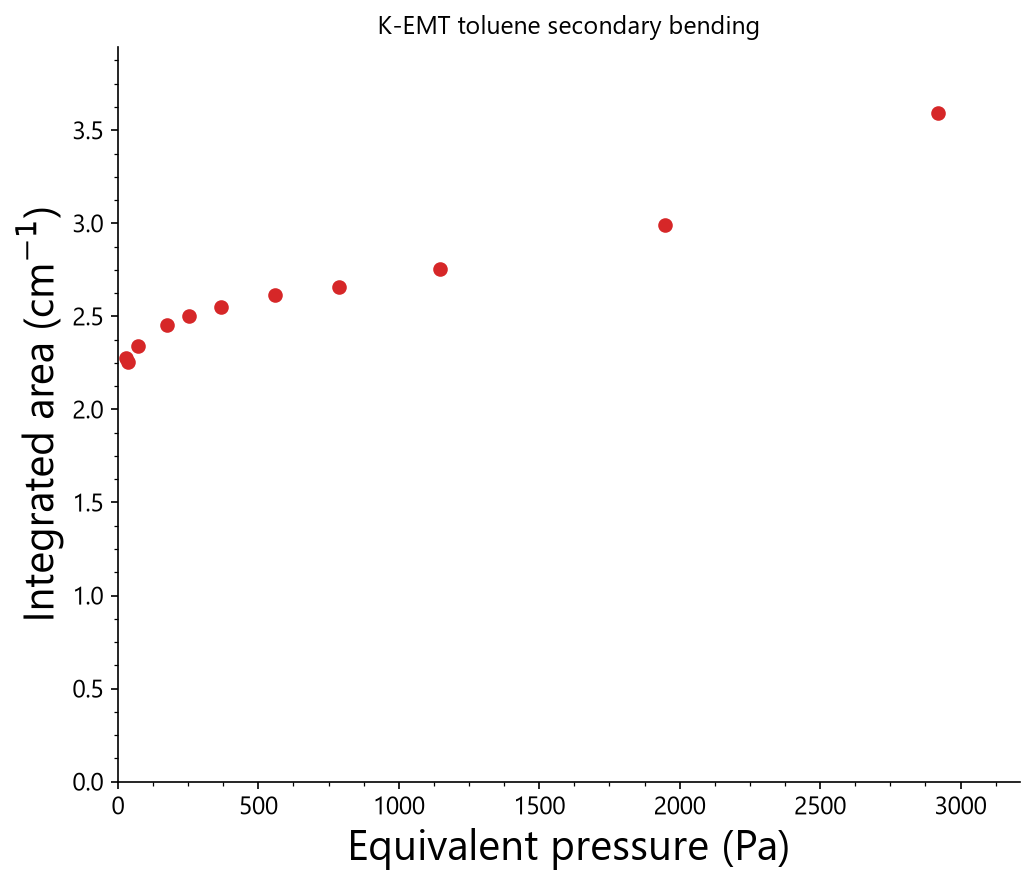

In [14]:
names_K, x_K = pressures_from_filenames(data_K)
y_K = np.abs(np.asarray(area_K_toluenesecondary.data)).ravel()

fig, ax1 = plt.subplots(1, 1, figsize=(7, 6))
ax1.plot(x_K, y_K, "o", color="C3")
ax1.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax1.set_xlabel("Equivalent pressure (Pa)")
ax1.set_title(f"K-EMT toluene secondary bending")
ax1.set_xlim(0, max(x_K) + 0.1*max(x_K))
ax1.set_ylim(0, max(y_K) + 0.1*max(y_K))
add_minor_ticks(ax1)
fig.tight_layout()
fig.savefig(outputpath / "K-EMT-toluene_secondary_bending_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

### Na-EMT vs K-EMT isotherms
Plots both isotherms on the same axes to compare the two samples. The x axis spans the full pressure range.

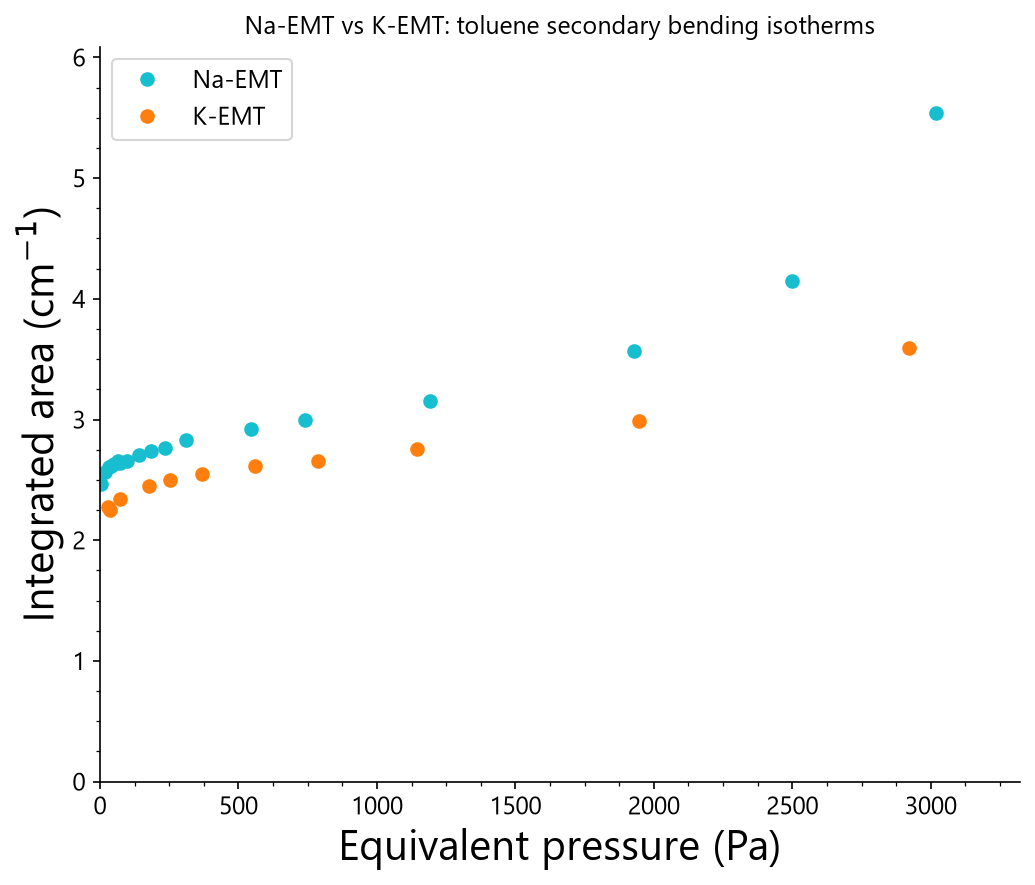

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot(x_Na, y_Na, "o", color="C9", label="Na-EMT")
ax.plot(x_K, y_K, "o", color="C1", label="K-EMT")
ax.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax.set_xlabel("Equivalent pressure (Pa)")
ax.set_title(f"Na-EMT vs K-EMT: toluene secondary bending isotherms")
ax.set_xlim(0, max(x_Na) + 0.1*max(x_Na))
ax.set_ylim(0, max(y_Na) + 0.1*max(y_Na))
add_minor_ticks(ax)
ax.legend(loc="upper left")
add_minor_ticks(ax)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT_vs_K-EMT-toluene_secondary_bending_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

### Isotherm comparison, low-pressure zoom
Same plot as above, with the x axis limited so the low-pressure region is readable.

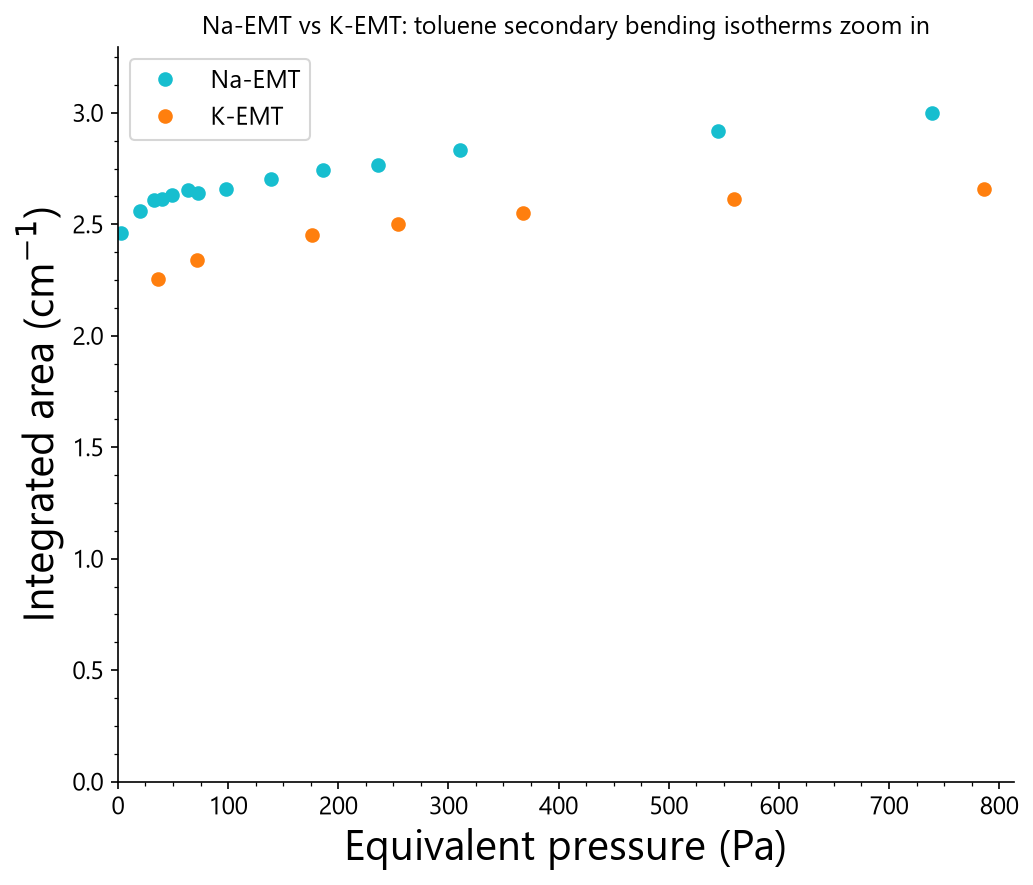

In [16]:

fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot(x_Na[:14], y_Na[:14], "o", color="C9", label="Na-EMT")
ax.plot(x_K[1:14], y_K[1:14], "o", color="C1", label="K-EMT")
ax.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax.set_xlabel("Equivalent pressure (Pa)")
ax.set_title(f"Na-EMT vs K-EMT: toluene secondary bending isotherms zoom in")
ax.set_xlim(0, max(x_Na[:14]) + 0.1*max(x_Na[:14]))
ax.set_ylim(0, max(y_Na[:14]) + 0.1*max(y_Na[:14]))
add_minor_ticks(ax)
ax.legend(loc="upper left")
add_minor_ticks(ax)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT_vs_K-EMT-toluene_secondary_bending_isotherm zoom in.svg", format="svg", bbox_inches="tight")
plt.show()

### Baseline of the CH stretching region
Fits a linear baseline for each sample and plots the baselines. The corrected spectra are used for the area integration.

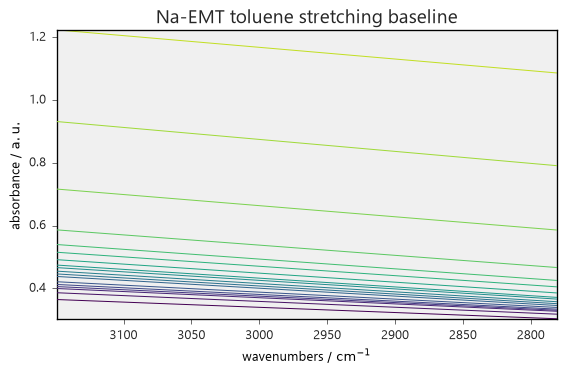

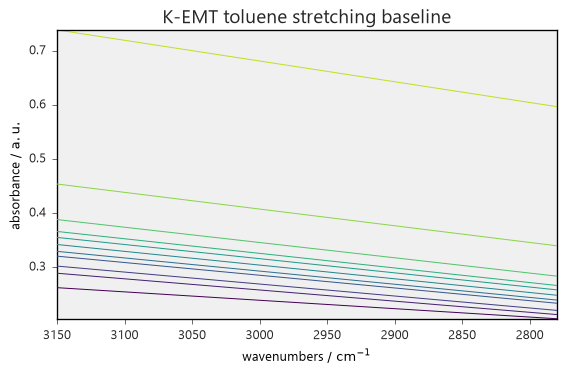

In [17]:
blc = scp.Baseline(model="polynomial", order=1)
_ = blc.fit(D_Nastretching[:, 3150.:2780.])

D_NastretchingCH_corrected = blc.corrected
baseline = blc.baseline
_ = baseline.plot(title='Na-EMT toluene stretching baseline')

_ = blc.fit(D_Kstretching[:, 3150.:2780.])
D_KstretchingCH_corrected = blc.corrected
baseline = blc.baseline
_ = baseline.plot(title='K-EMT toluene stretching baseline')

### Na-EMT CH stretching peaks
Plots the baseline-corrected CH stretching band and labels the peaks of the last spectrum. The figure is saved as SVG.

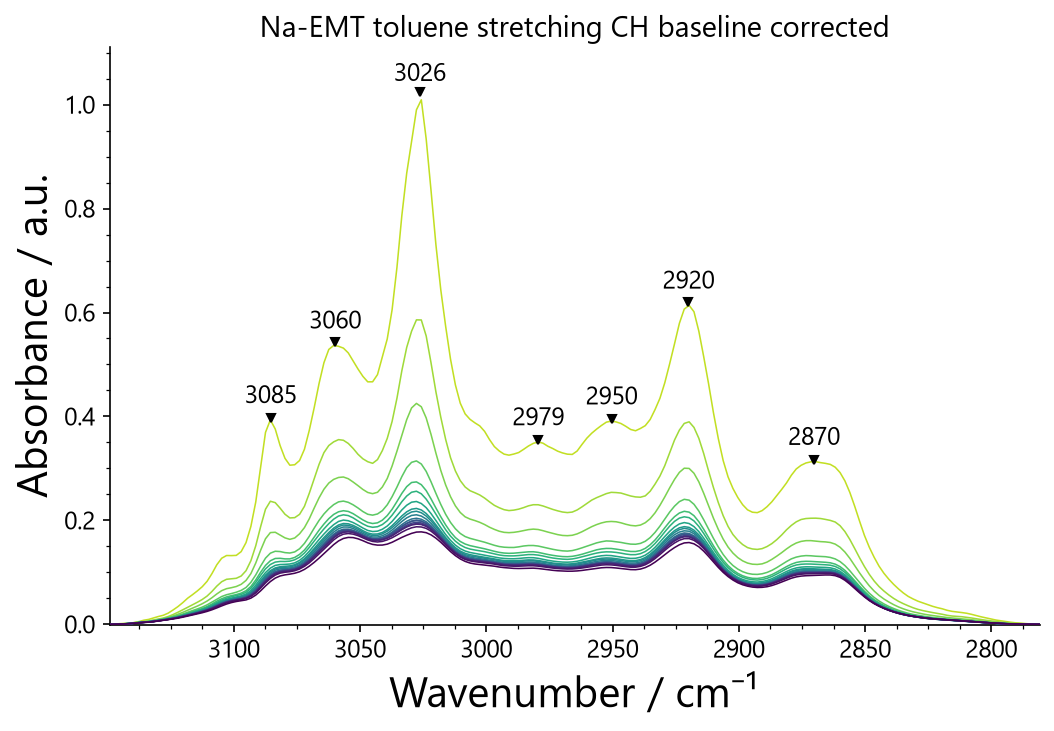

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_NastretchingCH_corrected.plot(ax=ax, title="Na-EMT toluene stretching CH baseline corrected")

spectrum = D_NastretchingCH_corrected[-1]
peaks, props = spectrum.find_peaks(distance="2 cm^-1", prominence=0.01)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=12)

ax.set_ylim(np.min(D_NastretchingCH_corrected.data), np.max(D_NastretchingCH_corrected.data) + 0.1*np.max(D_NastretchingCH_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "Na-EMT-toluenestretchingCH_corrected.svg", format="svg", bbox_inches="tight")

### K-EMT CH stretching peaks
Same as above for K-EMT.

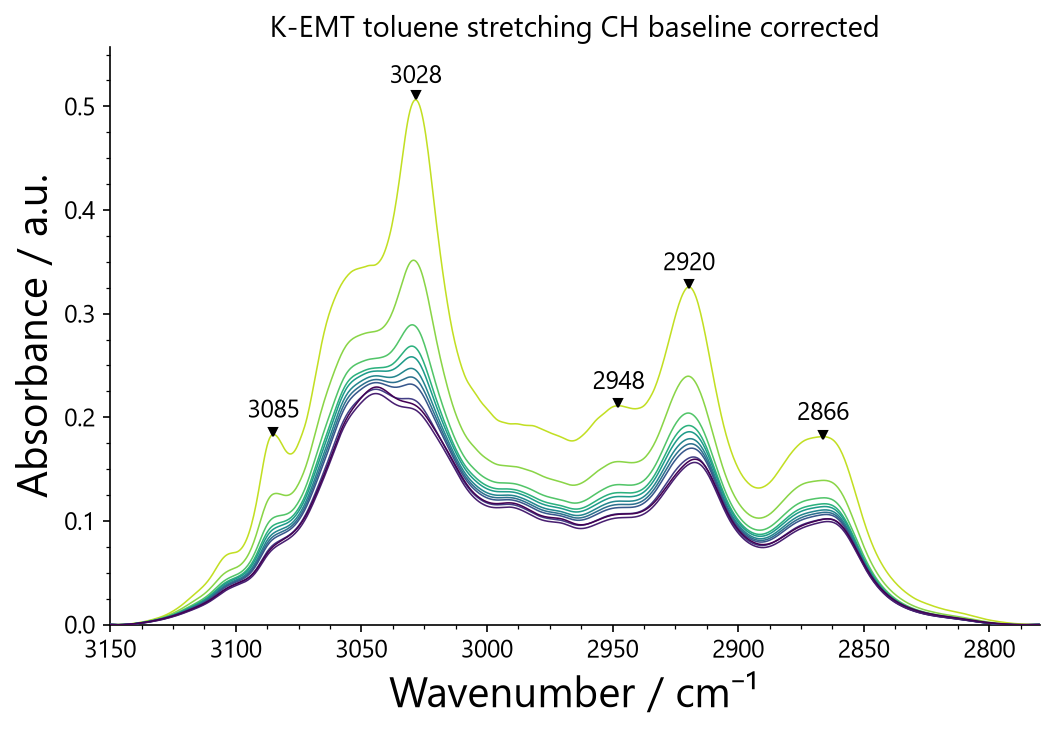

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_KstretchingCH_corrected.plot(ax=ax, title="K-EMT toluene stretching CH baseline corrected")

spectrum = D_KstretchingCH_corrected[-1]
peaks, props = spectrum.find_peaks(distance="2 cm^-1", prominence=0.001)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=12)

ax.set_ylim(np.min(D_KstretchingCH_corrected.data), np.max(D_KstretchingCH_corrected.data) + 0.1*np.max(D_KstretchingCH_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "K-EMT-toluenestretchingCH_corrected.svg", format="svg", bbox_inches="tight")

### Integrate the CH stretching band
Integrates each corrected CH stretching spectrum with the trapezoidal rule to obtain one area per dose, for Na-EMT and K-EMT.

In [20]:
area_Na_toluenestretchingCH = D_NastretchingCH_corrected.trapezoid(dim="x")
area_K_toluenestretchingCH = D_KstretchingCH_corrected.trapezoid(dim="x")

### Na-EMT isotherm
Identifies the pressure from the spectra name and then converts the equivalent pressures to Pa and plots the CH stretching area against pressure. The figure is saved as SVG.

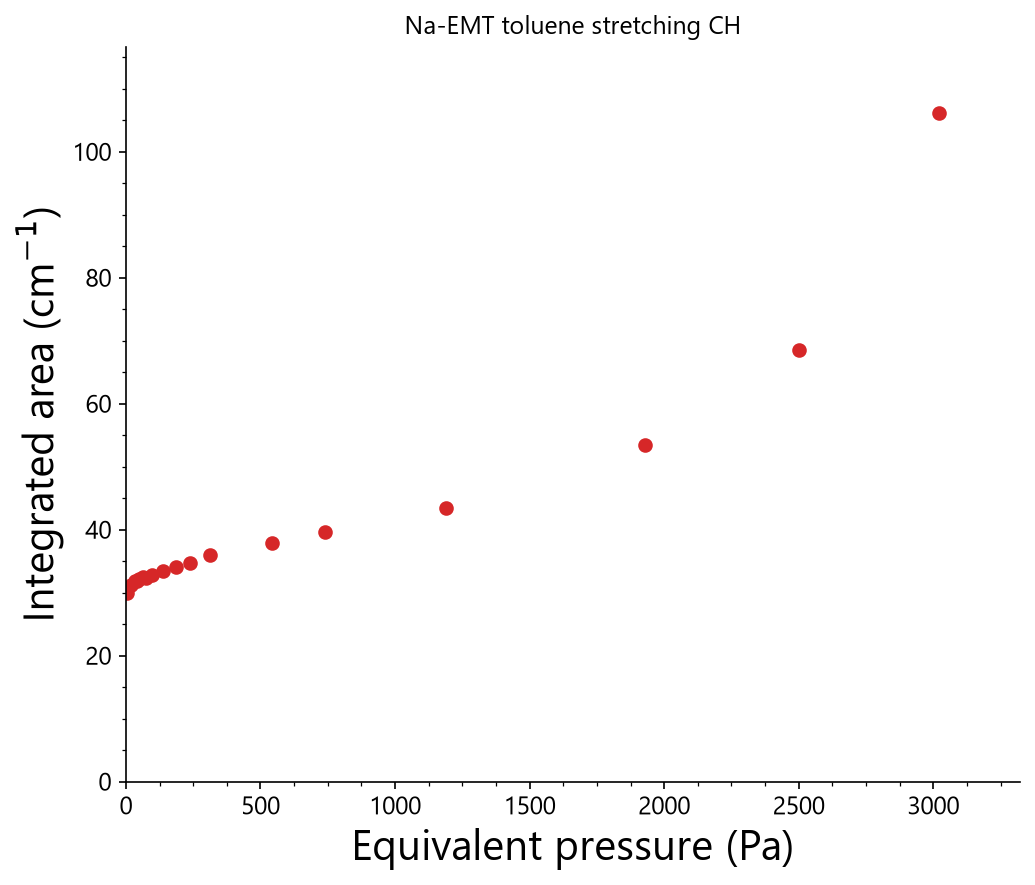

In [21]:
names_Na, x_Na = pressures_from_filenames(data_Na)

y_Na = np.abs(np.asarray(area_Na_toluenestretchingCH.data)).ravel()

fig, ax1 = plt.subplots(1, 1, figsize=(7, 6))
ax1.plot(x_Na, y_Na, "o", color="C3")
ax1.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax1.set_xlabel("Equivalent pressure (Pa)")
ax1.set_title(f"Na-EMT toluene stretching CH")
ax1.set_xlim(0, max(x_Na) + 0.1*max(x_Na))
ax1.set_ylim(0, max(y_Na) + 0.1*max(y_Na))
add_minor_ticks(ax1)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT-toluene_stretching_CH_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

### K-EMT isotherm
Same as previous cell.


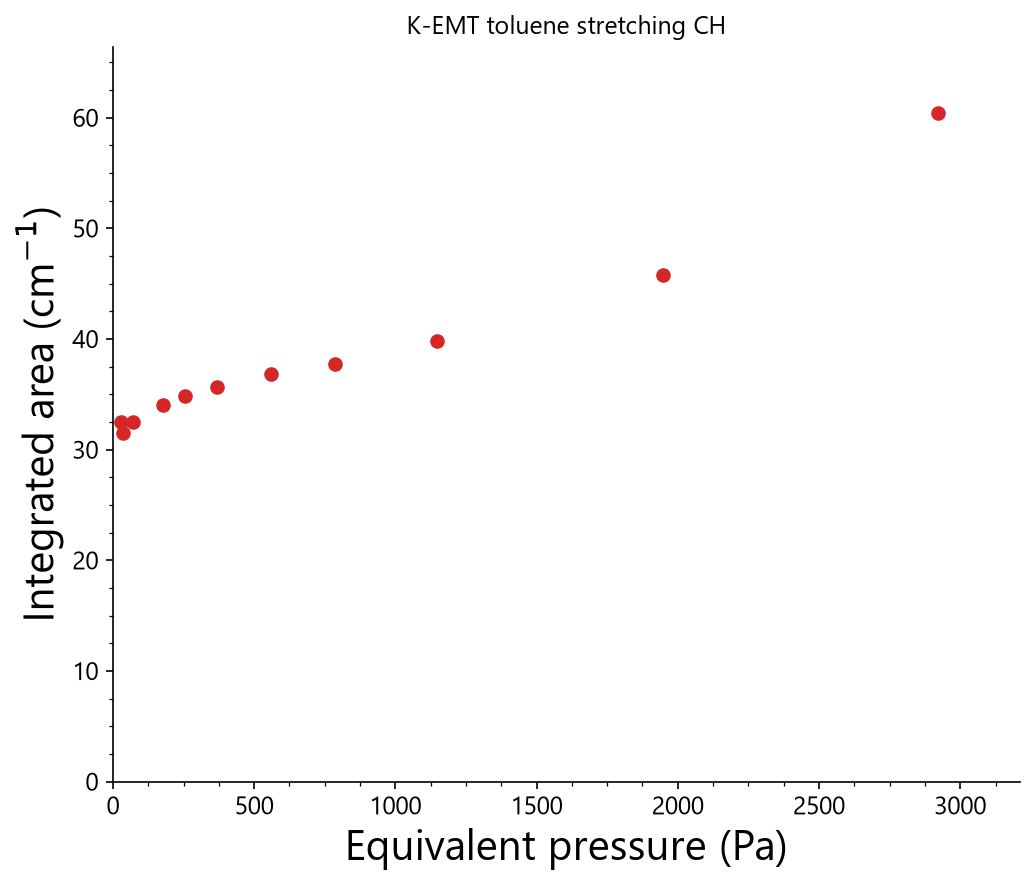

In [22]:
names_K, x_K = pressures_from_filenames(data_K)
y_K = np.abs(np.asarray(area_K_toluenestretchingCH.data)).ravel()

fig, ax1 = plt.subplots(1, 1, figsize=(7, 6))
ax1.plot(x_K, y_K, "o", color="C3")
ax1.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax1.set_xlabel("Equivalent pressure (Pa)")
ax1.set_title(f"K-EMT toluene stretching CH")
ax1.set_xlim(0, max(x_K) + 0.1*max(x_K))
ax1.set_ylim(0, max(y_K) + 0.1*max(y_K))
add_minor_ticks(ax1)
fig.tight_layout()
fig.savefig(outputpath / "K-EMT-toluene_stretching_CH_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

### Na-EMT vs K-EMT isotherms
Plots both isotherms on the same axes to compare the two samples. The x axis spans the full pressure range.

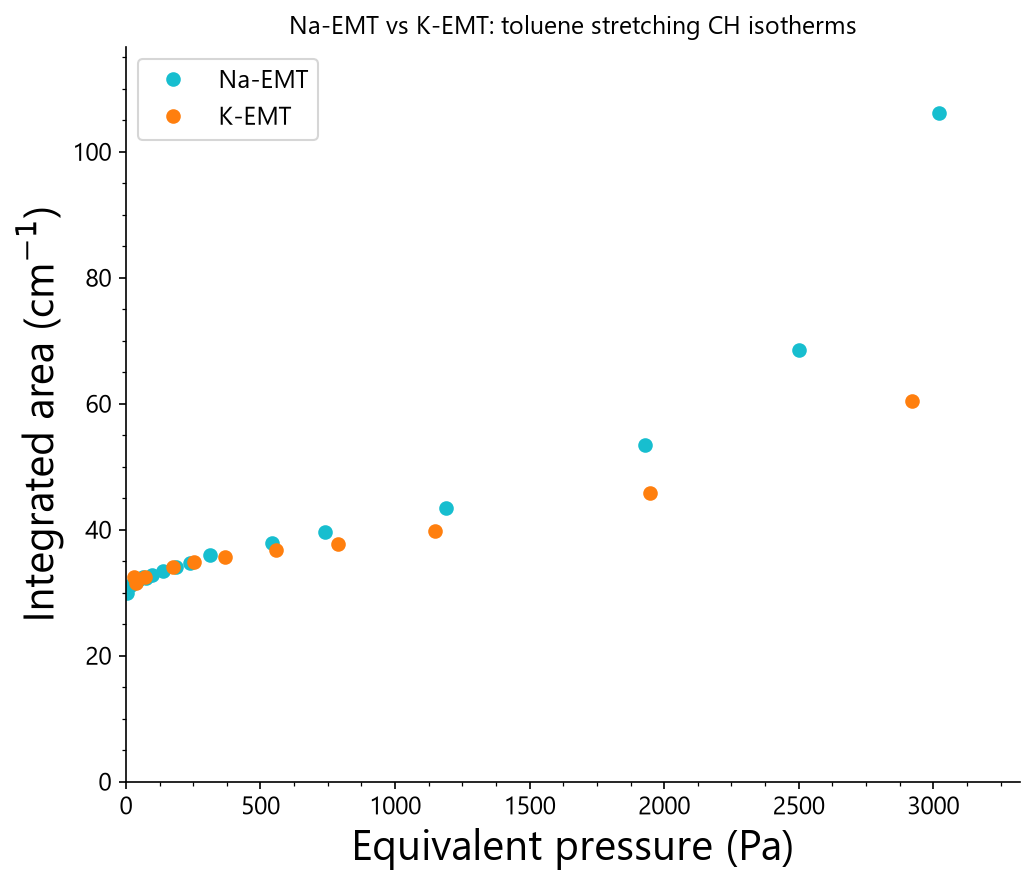

In [23]:
fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot(x_Na, y_Na, "o", color="C9", label="Na-EMT")
ax.plot(x_K, y_K, "o", color="C1", label="K-EMT")
ax.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax.set_xlabel("Equivalent pressure (Pa)")
ax.set_title(f"Na-EMT vs K-EMT: toluene stretching CH isotherms")
ax.set_xlim(0, max(x_Na) + 0.1*max(x_Na))
ax.set_ylim(0, max(y_Na) + 0.1*max(y_Na))
add_minor_ticks(ax)
ax.legend(loc="upper left")
add_minor_ticks(ax)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT_vs_K-EMT-toluene_stretching_CH_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

### Isotherm comparison, low-pressure zoom
Same plot as above, with the x axis limited so the low-pressure region is readable.

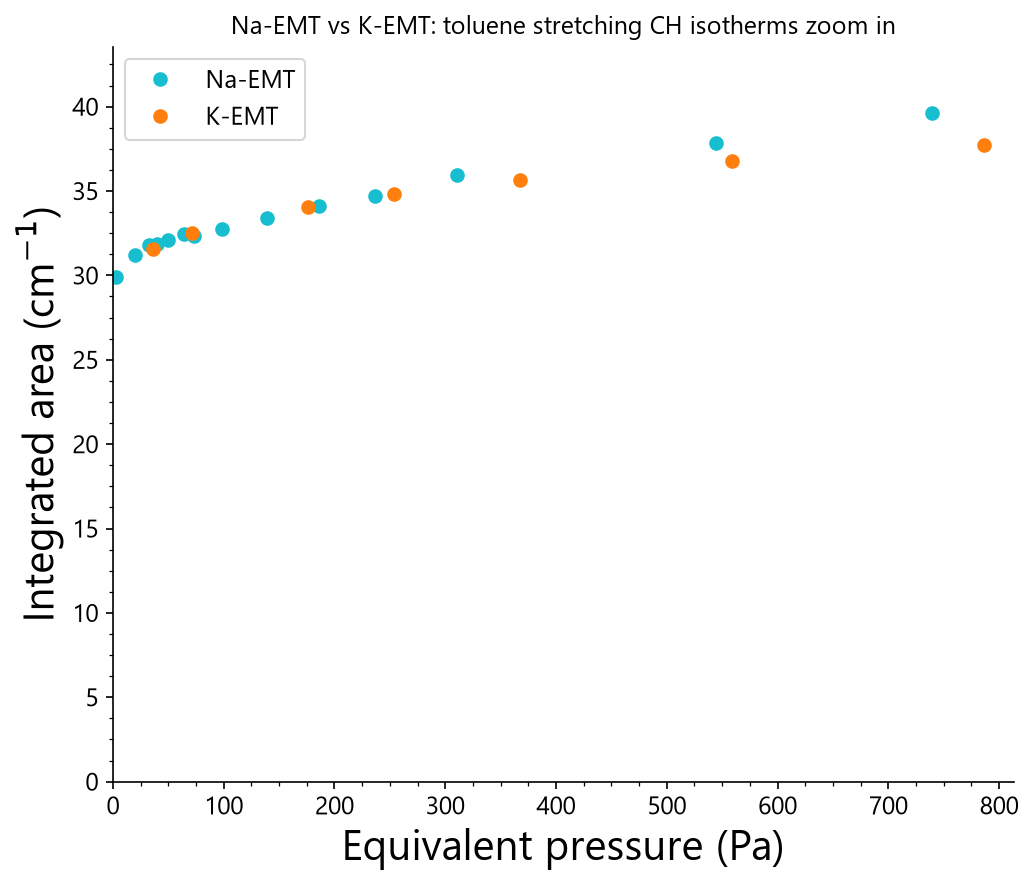

In [24]:

fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot(x_Na[:14], y_Na[:14], "o", color="C9", label="Na-EMT")
ax.plot(x_K[1:14], y_K[1:14], "o", color="C1", label="K-EMT")
ax.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax.set_xlabel("Equivalent pressure (Pa)")
ax.set_title(f"Na-EMT vs K-EMT: toluene stretching CH isotherms zoom in")
ax.set_xlim(0, max(x_Na[:14]) + 0.1*max(x_Na[:14]))
ax.set_ylim(0, max(y_Na[:14]) + 0.1*max(y_Na[:14]))
add_minor_ticks(ax)
ax.legend(loc="upper left")
add_minor_ticks(ax)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT_vs_K-EMT-toluene_isotherm zoom in.svg", format="svg", bbox_inches="tight")
plt.show()

### Baseline of the full stretching region
Fits a multivariate baseline for each sample.

INFO | This coordinate (3450.0) is outside the axis limits (3450.027-3799.079).
The closest limit index is returned
INFO | This coordinate (3800.0) is outside the axis limits (3450.027-3799.079).
The closest limit index is returned
INFO | This coordinate (3450.0) is outside the axis limits (3450.083-3800.106).
The closest limit index is returned


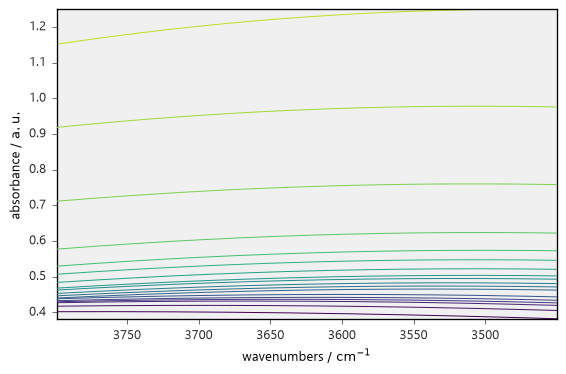

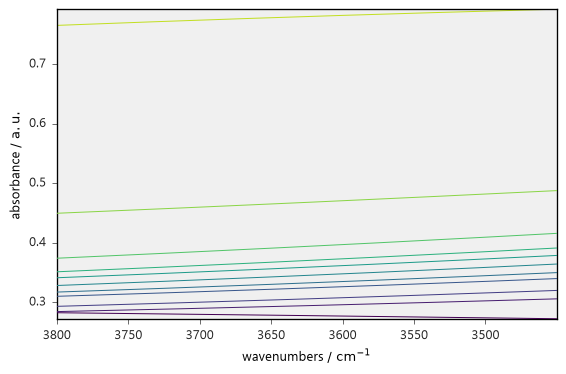

In [25]:
blc = scp.Baseline()
blc.multivariate = True                        # PCA-based baseline over the whole series
blc.model = "polynomial"
blc.order = 2                                  # low order: only two small anchor regions
blc.n_components = 3                          # 2 or 3 is typical
blc.ranges = ([3800., 3780.], [3500., 3450.])  # corners only
_ = blc.fit(D_Na[:, 3800.:3450.])

D_Na_stretching_corrected = blc.corrected
baseline = blc.baseline
_ = baseline.plot()

_ = blc.fit(D_K[:, 3800.:3450.])
D_K_stretching_corrected = blc.corrected
baseline = blc.baseline
_ = baseline.plot()

### Na-EMT stretching region peaks
Plots the corrected spectra and labels the band positions of the last spectrum. Positive peaks get a triangle above and negative peaks a triangle below. Only dips below the baseline are kept, so the valleys between bands are not labelled.

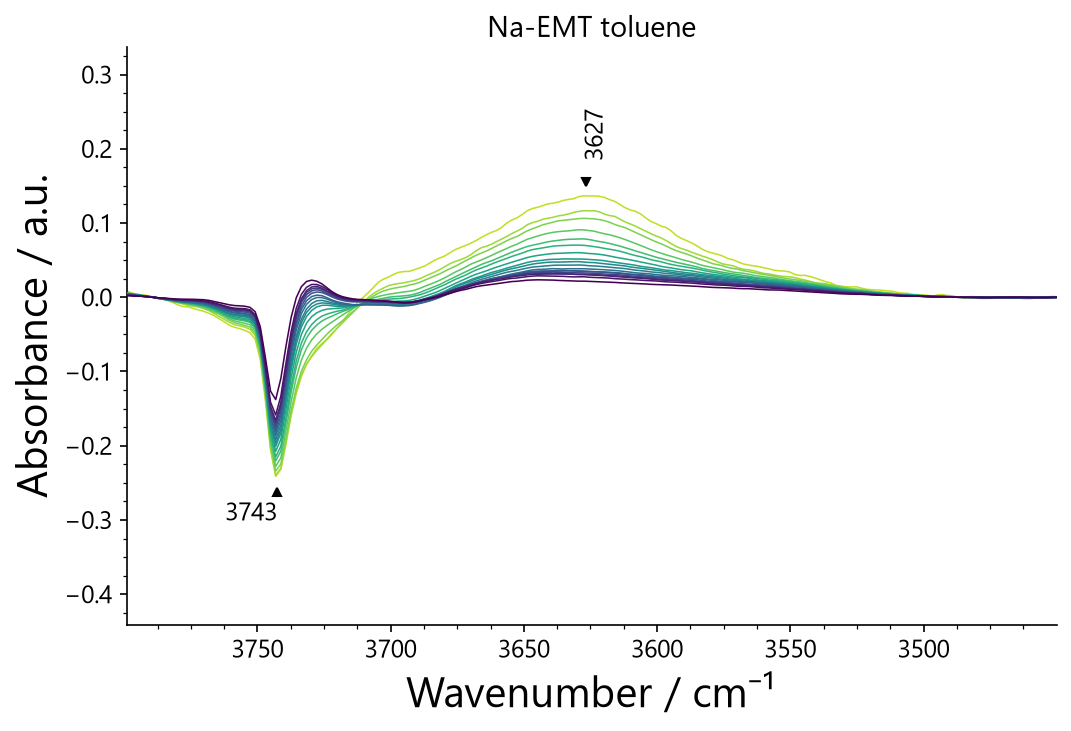

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_Na_stretching_corrected.plot(ax=ax, title="Na-EMT toluene")

spectrum = D_Na_stretching_corrected[-1]

pos, _ = spectrum.find_peaks(distance="5 cm^-1", prominence=0.01)
neg, _ = (-spectrum).find_peaks(distance="5 cm^-1", prominence=0.01)

xp = np.asarray(pos.x.data, dtype=float)
yp = np.asarray(pos.data, dtype=float)
xn = np.asarray(neg.x.data, dtype=float)
yn = -np.asarray(neg.data, dtype=float)

# keep only dips that go below the baseline (drops the 3025 / 2870 valleys)
keep = yn < -0.05
xn, yn = xn[keep], yn[keep]

span = np.max(D_Na_stretching_corrected.data) - np.min(D_Na_stretching_corrected.data)
off = 0.05 * span                            # marker offset in data units

ax.plot(xp, yp + off, "v", color="black", markersize=4)   # positive: triangle above
ax.plot(xn, yn - off, "^", color="black", markersize=4)   # negative: triangle below

for x, y in zip(xp, yp):
    ax.annotate(f"{x:.0f}", (x, y + off), xytext=(5, 10), textcoords="offset points", rotation = 90,
                ha="center", va="bottom", fontsize=12)
for x, y in zip(xn, yn):
    ax.annotate(f"{x:.0f}", (x, y - off), xytext=(0, -5), textcoords="offset points",
                ha="right", va="top", fontsize=12)

ax.set_ylim(np.min(D_Na_stretching_corrected.data) - 0.2, np.max(D_Na_stretching_corrected.data) + 0.2)
ax.set_xlabel("Wavenumber / cm\u207b\u00b9")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "Na-EMT-toluene_stretching_corrected.svg", format="svg", bbox_inches="tight")

### K-EMT stretching region peaks
Same as above for K-EMT.

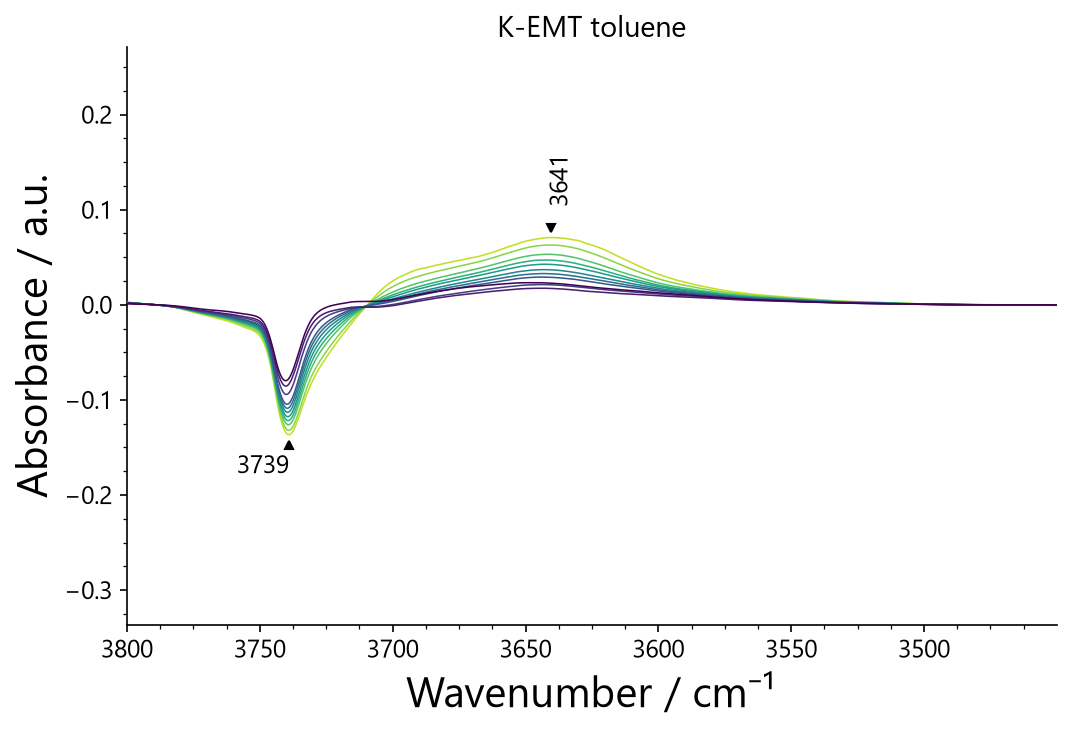

In [27]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_K_stretching_corrected.plot(ax=ax, title="K-EMT toluene")

spectrum = D_K_stretching_corrected[-1]

pos, _ = spectrum.find_peaks(distance="5 cm^-1", prominence=0.01)
neg, _ = (-spectrum).find_peaks(distance="5 cm^-1", prominence=0.01)

xp = np.asarray(pos.x.data, dtype=float)
yp = np.asarray(pos.data, dtype=float)
xn = np.asarray(neg.x.data, dtype=float)
yn = -np.asarray(neg.data, dtype=float)

# keep only dips that go below the baseline (drops the 3025 / 2870 valleys)
keep = yn < -0.05
xn, yn = xn[keep], yn[keep]


span = np.max(D_K_stretching_corrected.data) - np.min(D_K_stretching_corrected.data)
off = 0.05 * span                            # marker offset in data units

ax.plot(xp, yp + off, "v", color="black", markersize=4)   # positive: triangle above
ax.plot(xn, yn - off, "^", color="black", markersize=4)   # negative: triangle below

for x, y in zip(xp, yp):
    ax.annotate(f"{x:.0f}", (x, y + off), xytext=(5, 10), textcoords="offset points", rotation = 90,
                ha="center", va="bottom", fontsize=12)
for x, y in zip(xn, yn):
    ax.annotate(f"{x:.0f}", (x, y - off), xytext=(0, -5), textcoords="offset points",
                ha="right", va="top", fontsize=12)

ax.set_ylim(np.min(D_K_stretching_corrected.data) - 0.2, np.max(D_K_stretching_corrected.data) + 0.2)
ax.set_xlabel("Wavenumber / cm\u207b\u00b9")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "K-EMT-toluene_stretching_corrected.svg", format="svg", bbox_inches="tight")